# 022 Fine-tuning of the direct four-class classifier

**Overview.** The direct CLAM-MB for Non-cancer (N, PB, UDH, FEA), ADH, DCIS and IC of `02_1_vector_to_classifier_experimentation.ipynb` (section 7.6.1) uses settings selected for the seven-class problem and one training run. Here its learning rate, weight decay, dropout, weight of the coarse auxiliary loss, instance-loss sample size (`k_sample`) and the number of tiles per slide in training (`max_tiles`) are tuned by Bayesian optimisation. Every trial is a patient-grouped cross-validation over Training + Validation (`utils/mil_cv.py`); its score is the pooled out-of-fold macro-averaged F1. The chosen setting is confirmed with new seeds, its fold models are averaged into an ensemble, and the ensemble is evaluated once on the official Testing set. No choice uses the Testing set.

```mermaid
flowchart TD
    subgraph IN["Inputs"]
        FEAT[("FEATURES_DIR/UNI2-h/<br/>one .pt file per slide (from 01)")]
        LAB[("labels/BRACS.xlsx<br/>class, patient, official set")]
        OLD[("classifier/final/adh_four_class/<br/>direct 4-class model of 02_1")]
    end

    subgraph S3["3. Data"]
        D1["3.1 build_slide_table + load_bags"]
        D2["3.2 relabel_table<br/>Non-cancer / ADH / DCIS / IC"]
        D3["3.3 make_cv_folds<br/>patient-grouped, stratified"]
    end

    subgraph S4["4. Bayesian optimisation"]
        B1["objective_factory + run_study<br/>TPE sampler, one trial = one 5-fold CV"]
        B2["trials_table + plot_tuning"]
    end

    subgraph S5["5-6. Selection and confirmation"]
        C1["select_setting<br/>recall floor, best macro-F1,<br/>one-standard-error rule"]
        C2["cross_validate, 3 repeats,<br/>new seeds, top settings"]
    end

    subgraph S7["7. Ensemble"]
        N1["oof_by_repeat + single_vs_ensemble<br/>out-of-fold, no Testing"]
    end

    subgraph S8["8. Testing set, used once"]
        E1["predict_ensemble<br/>all fold models"]
        E2["class_views + bootstrap_views<br/>plot_final_results"]
        E3["paired_bootstrap_views<br/>vs the 02_1 model"]
    end

    OUT[("classifier/final/adh_four_class_tuned/<br/>ensemble_date-time.pt")]

    FEAT --> D1
    LAB --> D1
    D1 --> D2
    D2 --> D3
    D3 --> B1
    B1 --> B2
    B2 --> C1
    C1 --> C2
    C2 --> N1
    N1 --> E1
    E1 --> E2
    E1 --> E3
    OLD --> E3
    N1 --> OUT
```

## 1. Setup

The environment is recorded so the run can be reproduced.

In [1]:
# STEP 1: Standard-library imports and general-purpose third-party libraries
import sys
import matplotlib
import numpy as np
import optuna
import pandas as pd
import sklearn
import torch

# STEP 2: Print library versions for reproducibility
print('System Version:', sys.version)
print('PyTorch version:', torch.__version__)
print('Scikit-learn version:', sklearn.__version__)
print('Optuna version:', optuna.__version__)
print('Numpy version:', np.__version__)
print('Pandas version:', pd.__version__)
print('Matplotlib version:', matplotlib.__version__)

System Version: 3.14.7 (main, Aug 10 2026, 07:46:56) [GCC 16.1.1 20260728]
PyTorch version: 2.15.0+cu132
Scikit-learn version: 1.9.1
Optuna version: 5.1.0
Numpy version: 2.5.4
Pandas version: 3.1.1
Matplotlib version: 3.11.2


The model is trained on the GPU when one is available and on the CPU otherwise (`utils.device.get_device`).

In [2]:
# STEP 1: Select the device (pass e.g. get_device("cpu") to force the CPU)
from utils.device import get_device
DEVICE = get_device()

# STEP 2: Report it
print('Device:', DEVICE, '|', torch.cuda.get_device_name(DEVICE) if DEVICE.type == 'cuda' else 'no GPU, running on the CPU')

Device: cuda | NVIDIA RTX PRO 4500 Blackwell


The project's own building blocks are imported here. The search, the selection rule and the ensemble file are in `utils/mil_tuning.py`; the data, model, cross-validation and metric code is shared with notebooks 02 and 02_1.

In [3]:
# STEP 1: Standard-library imports
from pathlib import Path

# STEP 2: Import this project's own building blocks
from utils.dataset_overview import build_slide_table
from utils.mil_data import load_bags
from utils.mil_cv import cross_validate, fold_summary, make_cv_folds
from utils.mil_train import device_description, load_classifier, predict, predict_ensemble, set_seed
from utils.classification_metrics import evaluate_predictions
from utils.final_classifier import (bootstrap_views, class_views, format_differences, format_views, paired_bootstrap_views, plot_final_results, relabel_table, summary_across_sets)
from utils.mil_tuning import (DEFAULT_SPACE, objective_factory, oof_by_repeat, plot_tuning, run_study, save_ensemble, score_cv, select_setting, setting_from_row, setting_kwargs,
                              single_vs_ensemble, trials_table)

## 2. Constants

Every setting is defined here. The searched parameters and their ranges are `SPACE`; the first trial is `BASELINE`, the setting of notebook 02_1, so it is scored on the same folds as the others. Everything else is fixed: class weighting, tile dropout, the weight of the slide loss in CLAM-MB, the number of epochs and the early-stopping patience. The coarse auxiliary loss uses the tiers Non-cancer, ADH and {DCIS, IC}, which keep the order of severity of the four classes. `MIN_CLASS_RECALL` is a floor on the out-of-fold recall of every class that a setting must reach to be chosen; it is a clinical choice and is not tuned.

In [4]:
# Major variables
FEATURES_DIR = Path('/mnt/Scratch/phd_streamembed_features/level_1')    # STEP 1: Folder with one subfolder of .pt files per model
MODEL_NAME = 'UNI2-h'                                                   # STEP 2: Subfolder with the per-slide features
LABELS_FILE = Path('labels/BRACS.xlsx')                                 # STEP 3: Slide labels, patients and official split
MODEL_DIR = Path('classifier/final')                                    # STEP 4: Folder of the saved classifiers
SAVE_MODELS = True                                                      # STEP 5: Save the ensemble as ensemble_<date-time>.pt
SEED = 0                                                                # STEP 6: Seed of every random choice
N_FOLDS, EARLY_STOP_FRACTION = 5, 0.2                                   # STEP 7: Outer folds; share of the non-held-out slides used to pick the epoch (patient-grouped)
EPOCHS, PATIENCE = 100, 5                                               # STEP 8: Maximum epochs; early-stopping patience (counted after the warm-up)
WEIGHTING, TILE_DROPOUT, BAG_WEIGHT = 'sqrt', 0.5, 0.7                  # STEP 9: Class weighting, share of tiles removed per training bag, weight of the slide loss in CLAM-MB
N_TRIALS = 40                                                           # STEP 10: Trials of the Bayesian optimisation (finished trials; a restart continues the study)
STUDY_DIR = Path('outputs/02_2_tuning')                                 # STEP 11: Folder of the study (SQLite), the trials table
STUDY_NAME = 'adh_four_class'                                           # STEP 12: Name of the study inside the database
MIN_CLASS_RECALL = 0.40                                                 # STEP 13: Smallest out-of-fold recall that every class must have for a setting to be chosen
N_CONFIRM, REPEATS = 3, 3                                               # STEP 14: Settings confirmed with new seeds; repeats per fold (models of the ensemble = folds x repeats)
N_BOOT = 1000                                                           # STEP 15: Bootstrap resamples (patients) for the intervals
FOUR_MAPPING = {'N': 'Non-cancer', 'PB': 'Non-cancer', 'UDH': 'Non-cancer', 'FEA': 'Non-cancer', 'ADH': 'ADH', 'DCIS': 'DCIS', 'IC': 'IC'}   # STEP 16: BRACS class -> group (order = model outputs)
TIERS_4 = {'non-cancer': ['Non-cancer'], 'atypical': ['ADH'], 'malignant': ['DCIS', 'IC']}                                                  # STEP 17: Tiers of the coarse auxiliary loss
SPACE = DEFAULT_SPACE                                                   # STEP 18: Search ranges: (low, high) numeric, list = categorical (see utils/mil_tuning.py)
BASELINE = dict(lr=2e-4, weight_decay=1e-1, dropout=0.25, coarse_weight=0.0, k_sample=8, max_tiles=2048)   # STEP 19: First trial: the setting of notebook 02_1
FIXED = dict(epochs=EPOCHS, patience=PATIENCE, tile_dropout=TILE_DROPOUT, bag_weight=BAG_WEIGHT, weighted_val_loss=True, tiers=TIERS_4)   # STEP 20: train_model arguments that are not searched
STUDY_DIR.mkdir(parents=True, exist_ok=True)
set_seed(SEED)

## 3. Data

### 3.1 Slides and tile embeddings

The bags of tile embeddings (UNI2-h CLS tokens) are loaded once; the slide table holds the official split of BRACS.

In [5]:
# STEP 1: Label table with the official split and the bags of tile embeddings (float16)
table = build_slide_table(LABELS_FILE)
data = load_bags(FEATURES_DIR, MODEL_NAME, table)

Loading bags:   0%|          | 0/547 [00:00<?, ?it/s]

Slides with features: 547 of 547  |  tiles 5,748,673  |  tiles per slide: median 9441, min 9, max 35287  |  dim 1536
Per set (with features / labelled): Training 395/395, Validation 65/65, Testing 87/87
Tiling in the files: level 1, tile 448, stride 448


### 3.2 The four classes

Non-cancer groups N, PB, UDH and FEA; ADH, DCIS and IC keep their own class. The slides per class and part are listed; ADH has the fewest slides, so its measures are the most uncertain.

In [6]:
# STEP 1: Relabel the table and the bags for the four classes
table4, classes4 = relabel_table(data['table'], FOUR_MAPPING)
data4 = {**data, 'table': table4, 'classes': classes4}

# STEP 2: Slides per class and part
pd.crosstab(table4['label'], table4['set']).reindex(classes4)[['Training', 'Validation', 'Testing']]

set,Training,Validation,Testing
label,,,
Non-cancer,227,36,43
ADH,28,8,12
DCIS,40,9,12
IC,100,12,20


### 3.3 Cross-validation folds

The official Training and Validation slides are pooled and divided into patient-grouped, class-stratified folds; the Testing slides are in no fold. For every fold a part of the remaining slides is used to select the epoch and the rest to fit the model. The same folds are used by every trial, so the trials are compared on the same held-out slides.

In [7]:
# STEP 1: The folds (the Testing slides are left out of every fold)
folds = make_cv_folds(table4, N_FOLDS, SEED, EARLY_STOP_FRACTION)

# STEP 2: Slides and patients per part, and the held-out slides per class
fold_summary(folds, classes4)

,fold,fit,early stopping,held out,held-out patients,Non-cancer,ADH,DCIS,IC
0,0,294,74,92,31,52,8,10,22
1,1,291,77,92,34,53,7,10,22
2,2,293,75,92,33,52,7,10,23
3,3,293,75,92,30,53,7,9,23
4,4,295,73,92,30,53,7,10,22


## 4. Bayesian optimisation

One trial trains `N_FOLDS` models, one per fold, with a sampled setting and returns the pooled out-of-fold macro-averaged F1. The optimiser is the tree-structured Parzen estimator of optuna (Bergstra et al., 2011), which after ten random trials proposes settings from the results so far; the study is stored in SQLite, so a restart continues it. The number of slides per batch follows the tile cap (`batch_size_for`), so the tiles per batch, and the memory, stay about constant; this is part of each setting. A trial with a large cap takes several times longer than one at 2048 tiles.

In [8]:
# STEP 1: The objective (one trial = one cross-validation) and the study
objective = objective_factory(data4, folds, DEVICE, FIXED, WEIGHTING, SEED, SPACE)
study = run_study(STUDY_NAME, f'sqlite:///{STUDY_DIR / "study.db"}', objective, N_TRIALS, SEED, BASELINE)

[I 2026-11-16 07:09:41,821] A new study created in RDB with name: adh_four_class


  0%|          | 0/40 [00:00<?, ?it/s]

[I 2026-11-16 07:12:00,779] Trial 0 finished with value: 0.5592411990525199 and parameters: {'lr': 0.0002, 'weight_decay': 0.1, 'dropout': 0.25, 'coarse_weight': 0.0, 'k_sample': 8, 'max_tiles': 2048}. Best is trial 0 with value: 0.5592411990525199.


/home/guisazevedo/Projects/01_accamargo/phd_streamembed/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:304: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


[I 2026-11-16 07:15:11,558] Trial 1 finished with value: 0.5958235482745287 and parameters: {'lr': 0.000258817021493792, 'weight_decay': 0.05910317077425309, 'dropout': 0.40138168803582197, 'coarse_weight': 0.3, 'k_sample': 8, 'max_tiles': 8192}. Best is trial 1 with value: 0.5958235482745287.
[I 2026-11-16 07:18:39,547] Trial 2 finished with value: 0.5781048509976262 and parameters: {'lr': 6.491242543802532e-05, 'weight_decay': 0.001122233999416817, 'dropout': 0.516309922773969, 'coarse_weight': 0.3, 'k_sample': 8, 'max_tiles': 4096}. Best is trial 1 with value: 0.5958235482745287.


/home/guisazevedo/Projects/01_accamargo/phd_streamembed/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:304: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


... (47 outputs left out)

/home/guisazevedo/Projects/01_accamargo/phd_streamembed/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:304: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


[I 2026-11-16 08:44:22,452] Trial 35 finished with value: 0.609075904768657 and parameters: {'lr': 0.00029050686343553883, 'weight_decay': 0.12373649675291887, 'dropout': 0.4114272941582942, 'coarse_weight': 0.3, 'k_sample': 8, 'max_tiles': 8192}. Best is trial 35 with value: 0.609075904768657.


/home/guisazevedo/Projects/01_accamargo/phd_streamembed/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:304: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


[I 2026-11-16 08:47:42,434] Trial 36 finished with value: 0.5806360045632615 and parameters: {'lr': 0.00027147332914900264, 'weight_decay': 0.004316331202432282, 'dropout': 0.5061814075736272, 'coarse_weight': 0.3, 'k_sample': 4, 'max_tiles': 8192}. Best is trial 35 with value: 0.609075904768657.
[I 2026-11-16 08:50:17,774] Trial 37 finished with value: 0.5754259726062638 and parameters: {'lr': 0.00017727193487449775, 'weight_decay': 0.0015070035018752163, 'dropout': 0.5451802451189254, 'coarse_weight': 0.0, 'k_sample': 4, 'max_tiles': 2048}. Best is trial 35 with value: 0.609075904768657.
[I 2026-11-16 08:52:29,045] Trial 38 finished with value: 0.5627312930108683 and parameters: {'lr': 0.00028969977563415004, 'weight_decay': 0.0120815127943831, 'dropout': 0.4095663705613435, 'coarse_weight': 0.3, 'k_sample': 4, 'max_tiles': 2048}. Best is trial 35 with value: 0.609075904768657.
[I 2026-11-16 08:54:39,553] Trial 39 finished with value: 0.5717746148386393 and parameters: {'lr': 0.00031

### 4.1 Trials

Every finished trial with its parameters, the pooled out-of-fold macro-F1, the out-of-fold recall and F1 of each class, the standard deviation over folds and the minutes it took. Trial 0 is the setting of notebook 02_1.

In [9]:
# STEP 1: The trials table, best first (ties: lower log-loss)
trials = trials_table(study)
trials.to_csv(STUDY_DIR / 'trials.csv', index=False)
trials.round(3)

,trial,macro_f1,lr,weight_decay,dropout,coarse_weight,k_sample,max_tiles,f1_ADH,f1_DCIS,...,f1_Non-cancer,fold_se,fold_std,log_loss,mean_best_epoch,minutes,recall_ADH,recall_DCIS,recall_IC,recall_Non-cancer
0,35,0.609,0.000,0.124,0.411,0.3,8,8192.0,0.176,0.488,...,0.871,0.047,0.105,0.808,5.8,3.352,0.167,0.429,0.929,0.886
1,10,0.607,0.000,0.001,0.501,0.3,4,2048.0,0.233,0.462,...,0.860,0.031,0.069,0.702,7.4,2.262,0.278,0.429,0.866,0.852
2,4,0.605,0.000,0.003,0.164,0.3,4,2048.0,0.204,0.478,...,0.861,0.028,0.062,0.726,7.0,2.001,0.278,0.449,0.857,0.837
3,24,0.596,0.000,0.003,0.464,0.3,4,2048.0,0.200,0.437,...,0.874,0.037,0.083,0.661,7.2,2.331,0.222,0.388,0.866,0.882
4,1,0.596,0.000,0.059,0.401,0.3,8,8192.0,0.147,0.469,...,0.867,0.046,0.102,0.884,7.2,3.178,0.139,0.388,0.929,0.890
5,26,0.592,0.000,0.001,0.540,0.0,4,2048.0,0.208,0.440,...,0.852,0.033,0.075,0.752,7.6,2.358,0.278,0.408,0.857,0.829
6,30,0.591,0.000,0.010,0.543,0.0,4,2048.0,0.171,0.430,...,0.884,0.017,0.037,0.714,13.4,3.103,0.167,0.408,0.875,0.897
7,13,0.591,0.000,0.010,0.243,0.3,4,2048.0,0.203,0.413,...,0.873,0.033,0.073,0.739,8.8,2.437,0.222,0.388,0.866,0.875
8,25,0.590,0.000,0.003,0.434,0.5,4,2048.0,0.156,0.439,...,0.870,0.041,0.093,0.748,5.6,2.117,0.167,0.367,0.920,0.878
9,8,0.590,0.000,0.029,0.386,0.1,16,8192.0,0.138,0.452,...,0.871,0.049,0.109,0.725,4.8,2.792,0.111,0.388,0.946,0.897


### 4.2 Optimisation history, importance and tile cap

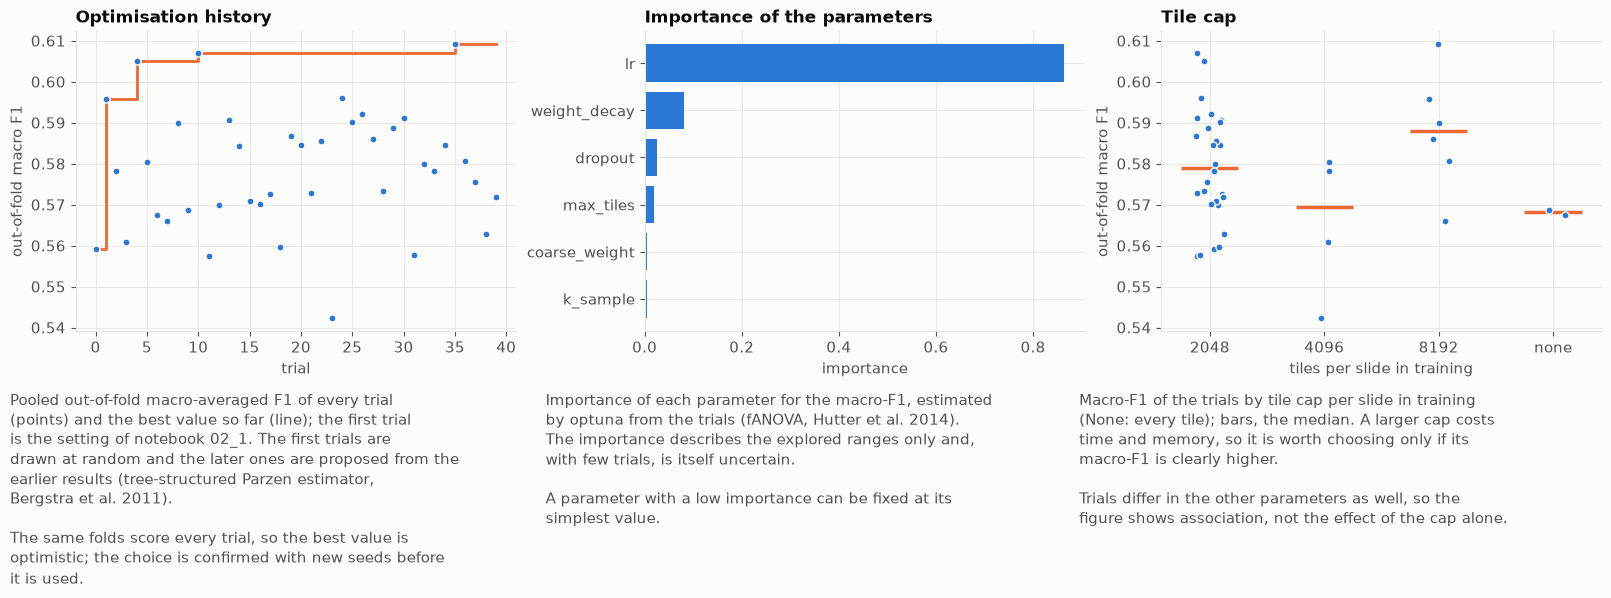

In [10]:
# STEP 1: Figure
fig_tuning = plot_tuning(study)

## 5. Selection

The final setting is chosen without the Testing set, in three steps: settings in which some class has an out-of-fold recall below `MIN_CLASS_RECALL` are removed; the best pooled macro-F1 is found among the rest; and among the settings within one standard error of it (the standard error of the fold macro-F1 values), the one with the cheapest tile cap, then the higher dropout and weight decay is taken (one-standard-error rule, Hastie et al., 2009). Macro-F1 gives every class the same weight, which suits the small ADH and DCIS classes; sensitivity alone is not used, since it is maximised by assigning every slide to the class.

In [13]:
# Check why the display fails
trials[[c for c in trials if c.startswith('recall_')]].describe().loc[['max']]

,recall_ADH,recall_DCIS,recall_IC,recall_Non-cancer
max,0.277778,0.44898,0.946429,0.939163


In [14]:
# STEP 1: Chosen setting and the candidates within one standard error of the best
# OBS: Uses min_class_recall=None as to discard the MIN_CLASS_RECALL, which might not  exist given ADH > 0.4
chosen, candidates = select_setting(trials, min_class_recall=None, classes=classes4)
display(candidates.round(3))
print('Chosen: trial', int(chosen['trial']), setting_from_row(chosen))

,trial,macro_f1,lr,weight_decay,dropout,coarse_weight,k_sample,max_tiles,f1_ADH,f1_DCIS,...,f1_Non-cancer,fold_se,fold_std,log_loss,mean_best_epoch,minutes,recall_ADH,recall_DCIS,recall_IC,recall_Non-cancer
0,35,0.609,0.000,0.124,0.411,0.3,8,8192.0,0.176,0.488,...,0.871,0.047,0.105,0.808,5.8,3.352,0.167,0.429,0.929,0.886
1,10,0.607,0.000,0.001,0.501,0.3,4,2048.0,0.233,0.462,...,0.860,0.031,0.069,0.702,7.4,2.262,0.278,0.429,0.866,0.852
2,4,0.605,0.000,0.003,0.164,0.3,4,2048.0,0.204,0.478,...,0.861,0.028,0.062,0.726,7.0,2.001,0.278,0.449,0.857,0.837
3,24,0.596,0.000,0.003,0.464,0.3,4,2048.0,0.200,0.437,...,0.874,0.037,0.083,0.661,7.2,2.331,0.222,0.388,0.866,0.882
4,1,0.596,0.000,0.059,0.401,0.3,8,8192.0,0.147,0.469,...,0.867,0.046,0.102,0.884,7.2,3.178,0.139,0.388,0.929,0.890
5,26,0.592,0.000,0.001,0.540,0.0,4,2048.0,0.208,0.440,...,0.852,0.033,0.075,0.752,7.6,2.358,0.278,0.408,0.857,0.829
6,30,0.591,0.000,0.010,0.543,0.0,4,2048.0,0.171,0.430,...,0.884,0.017,0.037,0.714,13.4,3.103,0.167,0.408,0.875,0.897
7,13,0.591,0.000,0.010,0.243,0.3,4,2048.0,0.203,0.413,...,0.873,0.033,0.073,0.739,8.8,2.437,0.222,0.388,0.866,0.875
8,25,0.590,0.000,0.003,0.434,0.5,4,2048.0,0.156,0.439,...,0.870,0.041,0.093,0.748,5.6,2.117,0.167,0.367,0.920,0.878
9,8,0.590,0.000,0.029,0.386,0.1,16,8192.0,0.138,0.452,...,0.871,0.049,0.109,0.725,4.8,2.792,0.111,0.388,0.946,0.897


Chosen: trial 19 {'lr': 0.0001620139546600851, 'weight_decay': 0.0034787723724151163, 'dropout': 0.5691837350093677, 'coarse_weight': 0.3, 'k_sample': 4, 'max_tiles': 2048}


## 6. Confirmation with new seeds

The chosen setting and the next best settings are trained again with `REPEATS` repeats per fold and seeds that the search did not use, because the best value of many trials is optimistic. The same selection rule is then applied to these scores, and the final setting is the one it chooses.

In [15]:
# STEP 1: The settings to confirm: the chosen one, then the best remaining ones
order = [int(chosen['trial'])] + [int(t) for t in trials[np.logical_and.reduce([trials[f'recall_{c}'] >= MIN_CLASS_RECALL for c in classes4])]['trial'] if int(t) != int(chosen['trial'])]
confirm_trials = order[:N_CONFIRM]

# STEP 2: Cross-validation of each with REPEATS repeats and new seeds
cvs, rows = {}, []
for number in confirm_trials:
    setting = setting_from_row(trials[trials['trial'] == number].iloc[0])
    cvs[number] = cross_validate('clam_mb', data4, folds, DEVICE, WEIGHTING, REPEATS, SEED + 5000, **setting_kwargs(setting, FIXED))
    rows.append({'trial': number, **setting, **score_cv(cvs[number], classes4)})
confirmation = pd.DataFrame(rows).sort_values(['macro_f1', 'log_loss'], ascending=[False, True]).reset_index(drop=True)
confirmation.round(3)

,trial,lr,weight_decay,dropout,coarse_weight,k_sample,max_tiles,macro_f1,log_loss,recall_Non-cancer,recall_ADH,recall_DCIS,recall_IC,f1_Non-cancer,f1_ADH,f1_DCIS,f1_IC,fold_std,fold_se
0,19,0.0,0.003,0.569,0.3,4,2048,0.562,0.68,0.882,0.111,0.347,0.893,0.869,0.113,0.378,0.889,0.086,0.038


The same selection rule is applied to the confirmation scores, which come from `REPEATS` models per fold, and gives the final setting and its fold models.

In [17]:
# STEP 1: The final setting by the same rule
# OBS: same here regarding min_class_recall
final, final_candidates = select_setting(confirmation, min_class_recall=None, classes=classes4)
final_trial, final_setting = int(final['trial']), setting_from_row(final)
final_cv = cvs[final_trial]
print('Final: trial', final_trial, final_setting)

Final: trial 19 {'lr': 0.0001620139546600851, 'weight_decay': 0.0034787723724151163, 'dropout': 0.5691837350093677, 'coarse_weight': 0.3, 'k_sample': 4, 'max_tiles': 2048}


## 7. Ensemble

The ensemble consists of the models of the final setting only: one per fold and repeat, `N_FOLDS` x `REPEATS` models, each trained on a different patient-grouped part of Training + Validation and stopped at its own epoch. A held-out slide is predicted by the models of its own fold and their probabilities are averaged, which gives the out-of-fold estimate below without the Testing set; on the Testing set all models predict every slide. Models of different settings are not mixed, because the same folds ranked the settings. The table compares each single repeat with the average of the repeats; an ensemble of the confirmed settings is shown for comparison.

In [18]:
# STEP 1: Single repeats against the ensemble, on the out-of-fold slides
per_repeat = oof_by_repeat(final_cv, data4, folds, DEVICE)
display(single_vs_ensemble(final_cv, per_repeat, classes4).round(3))

# STEP 2: For comparison, the average over the confirmed settings (the same folds ranked them, so this is optimistic)
from sklearn.metrics import f1_score
mixed = np.mean([cvs[t]['proba'] for t in confirm_trials], axis=0)
print('Macro F1 of the ensemble of the final setting:', round(score_cv(final_cv, classes4)['macro_f1'], 3),
      '| of the average over the confirmed settings:', round(f1_score(final_cv['y'], mixed.argmax(1), average='macro'), 3))

/home/guisazevedo/Projects/01_accamargo/phd_streamembed/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:304: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


,macro_f1,log_loss,recall_Non-cancer,recall_ADH,recall_DCIS,recall_IC
single model (repeat 0),0.557,0.710,0.875,0.111,0.367,0.848
single model (repeat 1),0.541,0.669,0.886,0.111,0.286,0.866
single model (repeat 2),0.535,0.790,0.856,0.083,0.306,0.902
ensemble (mean of repeats),0.562,0.680,0.882,0.111,0.347,0.893


Macro F1 of the ensemble of the final setting: 0.562 | of the average over the confirmed settings: 0.562


## 8. Evaluation on the Testing set

The Testing labels are read here for the first time. Every model of the ensemble predicts every Testing slide and the probabilities are averaged; the class with the highest probability is the prediction. For each class the measures are computed one class against the rest (for the macro row, the multi-class accuracy and the unweighted mean of the others), with 95% intervals from a bootstrap that resamples patients.

### 8.1 Confusion matrix, ROC curves and measures

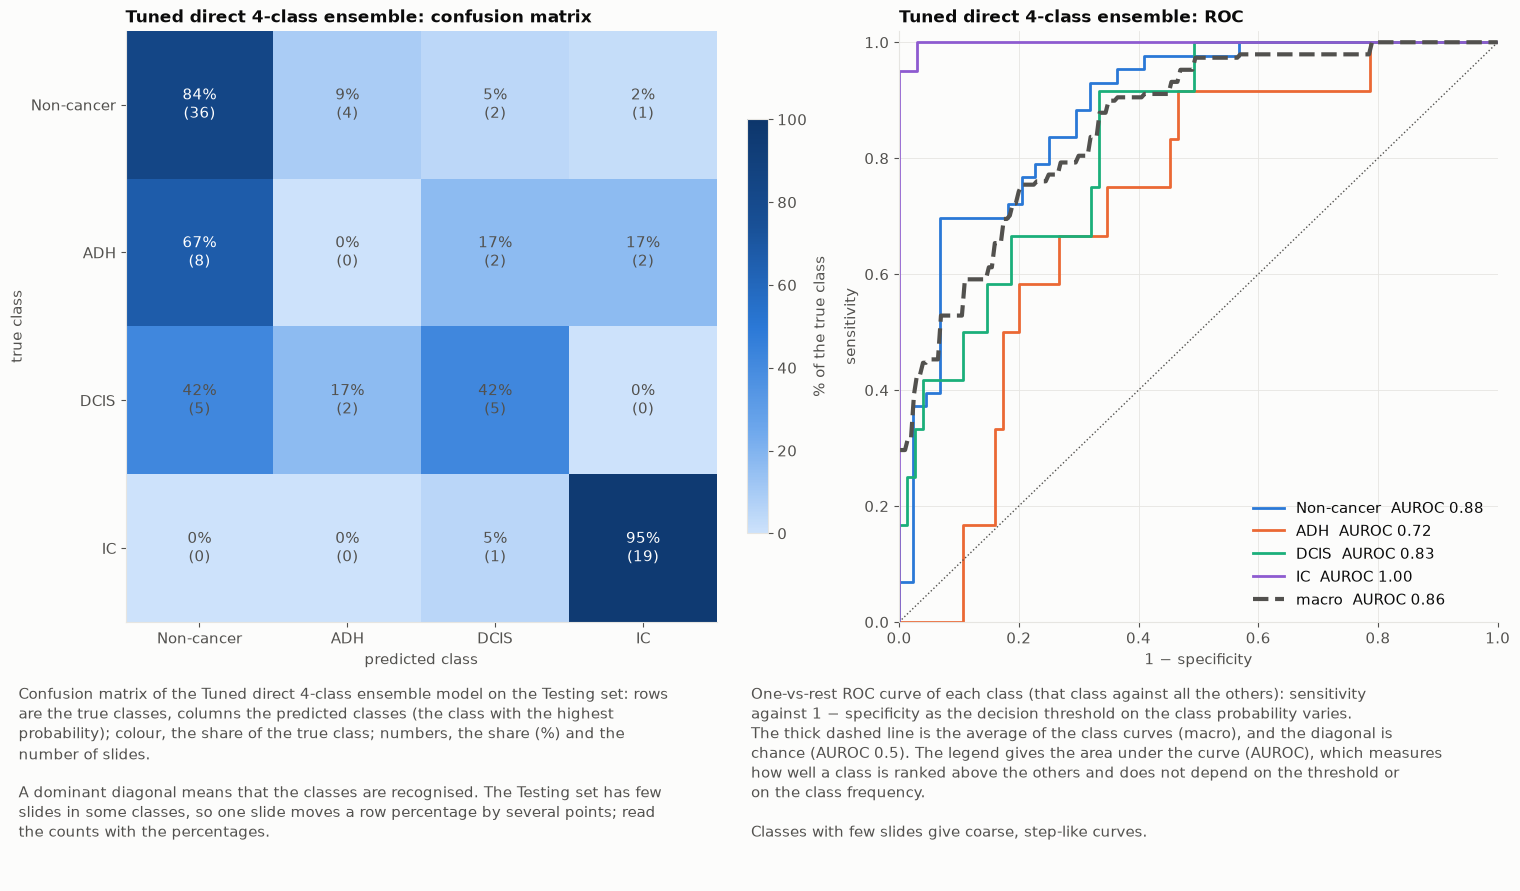

,accuracy,sensitivity,specificity,precision,f1,auroc
Non-cancer,"0.770 [0.667, 0.886]","0.837 [0.683, 0.967]","0.705 [0.500, 0.881]","0.735 [0.618, 0.851]","0.783 [0.667, 0.887]","0.881 [0.794, 0.952]"
ADH,"0.793 [0.723, 0.870]","0.000 [0.000, 0.000]","0.920 [0.849, 0.987]","0.000 [0.000, 0.000]","0.000 [0.000, 0.000]","0.717 [0.576, 0.855]"
DCIS,"0.862 [0.765, 0.952]","0.417 [0.125, 0.769]","0.933 [0.849, 0.989]","0.500 [0.143, 0.875]","0.455 [0.133, 0.727]","0.833 [0.706, 0.947]"
IC,"0.954 [0.900, 0.990]","0.950 [0.833, 1.000]","0.955 [0.889, 1.000]","0.864 [0.706, 1.000]","0.905 [0.788, 0.980]","0.999 [0.992, 1.000]"
macro,"0.690 [0.578, 0.803]","0.551 [0.449, 0.664]","0.878 [0.831, 0.922]","0.525 [0.421, 0.641]","0.535 [0.432, 0.624]","0.857 [0.786, 0.925]"


In [19]:
# STEP 1: Testing slides, in table order, and the ensemble probabilities
test = table4[table4['set'] == 'Testing'].reset_index(drop=True)
y_test = np.array([classes4.index(l) for l in test['label']])
patients_test = test['patient'].to_numpy()
proba_test = predict_ensemble(final_cv['runs'], data4, test['slide'].tolist(), DEVICE)['proba']

# STEP 2: Measures with patient-bootstrap intervals, figure and table
NAME = 'Tuned direct 4-class ensemble'
evaluation = evaluate_predictions(y_test, proba_test, classes4)
views = {NAME: class_views(y_test, proba_test, classes4)}
intervals = {NAME: bootstrap_views(y_test, proba_test, patients_test, classes4, N_BOOT, SEED)}
fig_test = plot_final_results(NAME, evaluation['confusion'], y_test, proba_test, classes4)
display(format_views(views[NAME], intervals[NAME]))

### 8.2 Comparison with the direct four-class model of notebook 02_1

The model saved by section 7.6.1 of notebook 02_1 (`classifier/final/adh_four_class/`) predicts the same Testing slides. The difference (tuned ensemble minus that model) comes with a 95% interval from a paired patient bootstrap, in which both models are scored on the same resamples. An interval that contains zero is not distinguishable from no change at this sample size (87 slides, 31 patients); ADH and DCIS have 12 Testing slides each, so a single slide changes their rows by several points.

In [20]:
# STEP 1: The previous direct four-class model (the latest file of its folder), on the same slides
previous_files = sorted((MODEL_DIR / 'adh_four_class').glob('classifier_model_*.pt'))
if not previous_files:
    print('No classifier in', MODEL_DIR / 'adh_four_class', ': run section 7.6 of notebook 02_1 first. Comparison skipped.')
else:
    previous = load_classifier(previous_files[-1], DEVICE)
    assert previous['classes'] == classes4, 'The class order of the two models must be the same'
    proba_previous = predict(previous['model'], data4, test['slide'].tolist(), DEVICE, previous['scaler'])['proba']

    # STEP 2: Measures of both, and the paired bootstrap of the difference
    views['Direct 4-class (02_1)'] = class_views(y_test, proba_previous, classes4)
    display(summary_across_sets(views).round(3))
    differences = paired_bootstrap_views(y_test, proba_test, proba_test.argmax(1), proba_previous, proba_previous.argmax(1), patients_test, classes4, N_BOOT, SEED)
    display(format_differences(differences))

,accuracy,sensitivity,specificity,precision,f1,auroc
Tuned direct 4-class ensemble,0.690,0.551,0.878,0.525,0.535,0.857
Direct 4-class (02_1),0.759,0.646,0.904,0.676,0.654,0.878


,accuracy,sensitivity,specificity,precision,f1,auroc
Non-cancer,"-0.046 [-0.106, +0.000]","-0.047 [-0.174, +0.000]","-0.045 [-0.116, +0.000]","-0.041 [-0.092, +0.000]","-0.043 [-0.116, +0.000]","-0.014 [-0.033, -0.002]"
ADH,"-0.057 [-0.113, -0.014]","-0.250 [-0.600, +0.000]","-0.027 [-0.063, +0.000]","-0.429 [-1.000, +0.000]","-0.316 [-0.636, +0.000]","-0.069 [-0.131, -0.004]"
DCIS,"+0.000 [-0.079, +0.053]","-0.083 [-0.222, +0.000]","+0.013 [-0.079, +0.068]","+0.000 [-0.252, +0.300]","-0.045 [-0.203, +0.113]","+0.001 [-0.040, +0.055]"
IC,"-0.034 [-0.080, +0.000]","+0.000 [+0.000, +0.000]","-0.045 [-0.111, +0.000]","-0.136 [-0.294, +0.000]","-0.070 [-0.167, +0.000]","-0.001 [-0.008, +0.000]"
macro,"-0.069 [-0.151, -0.018]","-0.095 [-0.196, -0.023]","-0.026 [-0.053, -0.009]","-0.151 [-0.318, -0.002]","-0.119 [-0.231, -0.019]","-0.021 [-0.043, +0.002]"


## 9. Save

The ensemble is written to one file with the weights, scaler and settings of every model (`utils.mil_tuning.save_ensemble`; `load_ensemble` returns the models for `predict_ensemble`). The configuration records the searched ranges, the final setting and the study.

In [21]:
# STEP 1: What is needed to reproduce and to reuse the ensemble
config = dict(
    seed=SEED, n_folds=N_FOLDS, repeats=REPEATS, early_stop_fraction=EARLY_STOP_FRACTION, weighting=WEIGHTING, fixed={k: v for k, v in FIXED.items() if k != 'tiers'}, tiers=TIERS_4,
    final_trial=final_trial, final_setting=final_setting, space={k: list(v) if isinstance(v, (tuple, list)) else v for k, v in SPACE.items()}, n_trials=N_TRIALS, min_class_recall=MIN_CLASS_RECALL,
    mapping=FOUR_MAPPING, classes=classes4, features_dir=str(FEATURES_DIR), model_name=MODEL_NAME, tile_params=data['tile_params'], device=device_description(DEVICE),
    versions=dict(torch=torch.__version__, sklearn=sklearn.__version__, numpy=np.__version__, pandas=pd.__version__, optuna=optuna.__version__), dropped_slides=data['missing'],
)

# STEP 2: Save the models of the ensemble
if SAVE_MODELS:
    path = save_ensemble(final_cv['runs'], MODEL_DIR / 'adh_four_class_tuned', config)
    print('Ensemble of', len(final_cv['runs']), 'models saved to', path.resolve())
else:
    print('SAVE_MODELS is False: nothing was written.')

Ensemble of 15 models saved to /home/guisazevedo/Projects/01_accamargo/phd_streamembed/classifier/final/adh_four_class_tuned/ensemble_2026-11-16_09-13-59.pt
